# PWC-Net replication: in vivo EPE in mm, face to face with the paper

**Why training only shows px**

- `train.log`, `history.json` and "best val px" are the *dense* flow EPE over the myocardium, in pixels. It is used to pick `best.pt`.
- The paper's Table 2 "EPE (mm)" is a different measurement. The 72-point endocardial contour is propagated from frame 1 through the predicted flow and compared with MITT's tracked points, in mm.
- That mm score is computed separately by `paper_evaluate.py` when a run finishes, and saved to `<run>/eval_invivo.json` (best.pt) and `eval_invivo_step<N>.json` (snapshots). The `queue_status` columns "paper val mm" and "paper test mm" show it, but nothing else displays it. The old `pwcnet_results.ipynb` is from the earlier pipeline and shows px only.

**Face to face means the same protocol as Table 2**

- 2ch view only (the paper scored 2ch only).
- The paper's pixel spacing, which swaps x and y. "Corrected" uses each axis's own spacing.
- Each patient scored by the fold that never trained on it, with all 6 folds pooled.
- Mean ± SD across sequences.

The notebook only reads saved results, so it never touches the GPU and can run beside a training. Section 3 reads MITT fields from disk and runs on the CPU.

In [1]:
import json, os, sys
from pathlib import Path

os.environ.setdefault("MKL_THREADING_LAYER", "TBB")
ROOT = Path.cwd()
while not (ROOT / "motion_estimator").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from motion_estimator.methods.pwcnet.paper_metrics import contour_epe

ME = ROOT / "motion_estimator"
RUNS = ME / "artifacts" / "paper-runs"
INVIVO_CACHE = ME / "artifacts" / "invivo-cache"             # frames 1..n, MITT points, pixel spacing
IV_FLOW_CACHE = ME / "artifacts" / "paper-cache" / "iv"      # MITT dense fields (training targets)
PAPER_RESULTS = Path(r"F:\PHD\Experiments\Journal_MotionEstimation\Results\InVivo")

# Paper, Table 2: in vivo EPE (mm), mean +- SD across sequences, 2ch, paper's spacing. NaN = not on file yet
PAPER = {
    "MS0_IV85":  (1.39, np.nan),
    "MS12_IV85": (1.30, 0.44),
    "MS23_IV85": (1.17, 0.40),
    "MS35_IV85": (1.19, 0.36),
    "MS47_IV85": (1.10, 0.37),
    "MS30_IV50": (np.nan, np.nan),
    "MS47_IV0":  (4.71, 0.44),
    "MS100_IV0": (4.70, np.nan),
}

# Same palette as paper_overview.py; colour follows the start (scratch / pretrained), never the rank
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
VARIANT_COLOUR = {"scratch": SERIES[0], "pretrained": SERIES[1], "pretrained150k": SERIES[2]}
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2,
                     "ytick.color": INK_2, "axes.labelcolor": INK_2, "axes.titlelocation": "left"})


def mean_sd(values) -> str:
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    return f"{v.mean():.2f} ± {v.std(ddof=1):.2f}" if len(v) > 1 else "-"


def strip(ax, groups: dict, colours: dict, reference=None):
    # One dot per clip, mean +- SD beside it; reference = (mean, sd) drawn as a dashed line and band
    rng = np.random.default_rng(0)
    for i, (label, values) in enumerate(groups.items()):
        v = np.asarray(values, float)
        v = v[np.isfinite(v)]
        ax.scatter(i + rng.uniform(-0.14, 0.14, len(v)), v, s=16, color=colours[label], alpha=0.55, linewidths=0)
        ax.errorbar(i + 0.3, v.mean(), yerr=v.std(ddof=1), fmt="o", color=INK, ms=7, capsize=4, lw=1.5)
        ax.annotate(f"{v.mean():.2f}", (i + 0.38, v.mean()), va="center", fontsize=9, color=INK)
    if reference is not None and np.isfinite(reference[0]):
        mean, sd = reference
        ax.axhline(mean, color=INK_2, linestyle="--", linewidth=1.5, label=f"paper {mean:.2f} mm")
        if np.isfinite(sd):
            ax.axhspan(mean - sd, mean + sd, color=GRID, alpha=0.7, zorder=0, label="paper ± SD")
        ax.legend(frameon=False, fontsize=8.5, loc="upper right")
    ax.set_xticks(range(len(groups)), list(groups))
    ax.set_xlim(-0.5, len(groups) - 0.2)

## 1. Every scored run

One row per run and clip, read from `eval_invivo.json` (best.pt). The 6 clips where MITT and the cycle have different lengths are dropped; the paper also left out IV02, IV27 and IV43.

In [2]:
def load_scores(checkpoint: str = "best.pt") -> pd.DataFrame:
    name = "eval_invivo.json" if checkpoint == "best.pt" else f"eval_invivo_{Path(checkpoint).stem}.json"
    rows = []
    for path in sorted(RUNS.glob(f"*/*/{name}")):
        config = json.loads((path.parent / "config.json").read_text(encoding="utf-8"))
        run, test = path.parent.parent.name, config["test"]
        variant = run[len(test):].lstrip("_") or "scratch"
        for r in json.loads(path.read_text(encoding="utf-8"))["sequences"]:
            if not r.get("skipped"):
                rows.append({"test": test, "variant": variant, "run": run, "fold": path.parent.name,
                             "key": r["key"], "view": r["view"], "epe_mm": r["epe_mm"],
                             "epe_mm_paper_exact": r["epe_mm_paper_exact"]})
    return pd.DataFrame(rows)


scores = load_scores()
scores.groupby(["run", "fold"]).size().unstack("fold").fillna(0).astype(int)

fold,fold0,fold1,fold2,single
run,,,,
MS47_IV0,0,0,0,230
MS47_IV0_pretrained,0,0,0,230
MS47_IV0_pretrained150k,0,0,0,230
MS47_IV85,40,38,0,0
MS47_IV85_pretrained,40,0,0,0
MS47_IV85_pretrained150k,40,38,40,0


## 2. Face to face with Table 2

- **paper protocol** is 2ch with the paper's spacing. This is the column to put next to Table 2.
- **corrected** is 2ch + 4ch with the correct spacing. This is the number to report for the new work.
- **95% CI** is for our mean across clips. The paper only gives a point value here, because its per-sequence results for these tests are not on file.

In [3]:
rows = []
for (test, variant, run), group in scores.groupby(["test", "variant", "run"], sort=False):
    two = group[group.view == "2ch"].epe_mm_paper_exact.dropna()
    paper_mean, paper_sd = PAPER.get(test, (np.nan, np.nan))
    folds = sorted(group.fold.unique())
    half = 1.96 * two.std(ddof=1) / np.sqrt(len(two))
    rows.append({
        "test": test, "start": variant,
        "folds": "single" if folds == ["single"] else f"{len(folds)}/6",
        "2ch clips": len(two),
        "ours, paper protocol": mean_sd(two),
        "95% CI": f"{two.mean() - half:.2f}..{two.mean() + half:.2f}",
        "paper Table 2": "-" if np.isnan(paper_mean) else f"{paper_mean:.2f}" + ("" if np.isnan(paper_sd) else f" ± {paper_sd:.2f}"),
        "ours - paper": "-" if np.isnan(paper_mean) else f"{two.mean() - paper_mean:+.2f}",
        "ours, corrected (2ch+4ch)": mean_sd(group.epe_mm),
    })
face = pd.DataFrame(rows)
face

,test,start,folds,2ch clips,"ours, paper protocol",95% CI,paper Table 2,ours - paper,"ours, corrected (2ch+4ch)"
0,MS47_IV0,scratch,single,115,1.75 ± 0.48,1.67..1.84,4.71 ± 0.44,-2.96,1.93 ± 0.56
1,MS47_IV0,pretrained,single,115,1.60 ± 0.48,1.51..1.68,4.71 ± 0.44,-3.11,1.66 ± 0.49
2,MS47_IV0,pretrained150k,single,115,1.65 ± 0.47,1.57..1.74,4.71 ± 0.44,-3.06,1.81 ± 0.55
3,MS47_IV85,scratch,2/6,39,1.05 ± 0.55,0.88..1.22,1.10 ± 0.37,-0.05,1.08 ± 0.47
4,MS47_IV85,pretrained,1/6,20,1.18 ± 0.72,0.86..1.50,1.10 ± 0.37,+0.08,1.14 ± 0.60
5,MS47_IV85,pretrained150k,3/6,59,1.02 ± 0.50,0.89..1.14,1.10 ± 0.37,-0.08,1.02 ± 0.43


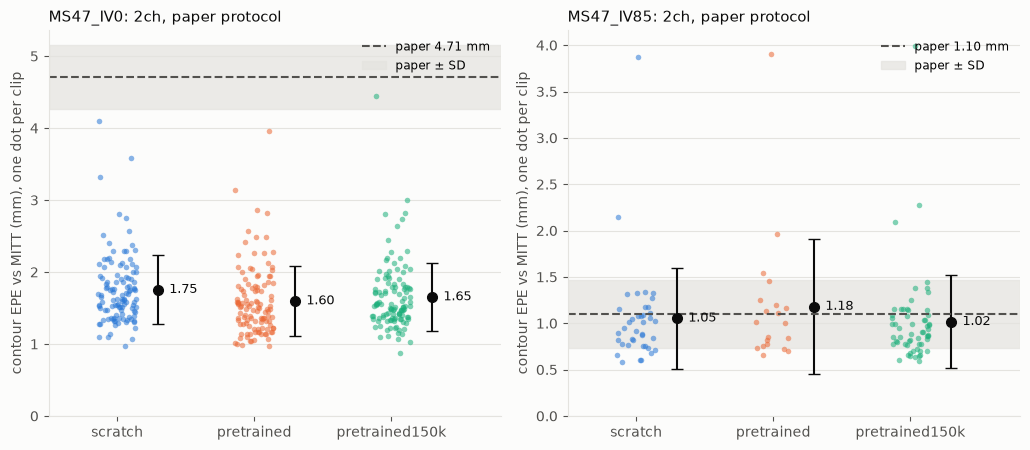

In [4]:
tests = list(dict.fromkeys(scores.test))
fig, axes = plt.subplots(1, len(tests), figsize=(5.2 * len(tests), 4.6), squeeze=False)
for ax, test in zip(axes[0], tests):
    sub = scores[(scores.test == test) & (scores.view == "2ch")]
    groups = {v: sub[sub.variant == v].epe_mm_paper_exact for v in VARIANT_COLOUR if v in set(sub.variant)}
    strip(ax, groups, VARIANT_COLOUR, PAPER.get(test))
    ax.set_title(f"{test}: 2ch, paper protocol", fontsize=11, color=INK)
    ax.set_ylabel("contour EPE vs MITT (mm), one dot per clip")
    ax.set_ylim(0, None)
fig.tight_layout()

## 3. Is the mm number right? Three checks

- **3a. The metric reproduces Table 2.** Feed the paper's *own* predicted contours (saved by the MATLAB pipeline on F:) through our Python metric. If the port is right, it gives back Table 2.
- **3b. Two anchors on our test clips.** The *no motion* anchor freezes the contour at frame 1, which is the score of doing nothing. The *MITT field* anchor propagates MITT's own dense field (the in vivo training target) exactly as a prediction would be. This is how the target itself scores. It is **not** a floor: MITT's dense field does not exactly reproduce MITT's tracked points, and that gap adds up over the cycle (see 3b, second part). A model must beat no motion by far and land near the MITT field.
- **3c. The spacing.** Shows how much the paper's swapped x/y spacing changes the numbers.

In [5]:
from motion_estimator.loaders.images import _matio

OLD_RUNS = {"Test_3": "MS12_IV85", "Test_4": "MS23_IV85", "Test_5": "MS35_IV85"}  # folders that hold Table 2's models


def paper_own_contours(folder: str, variant: str = "unCorr_prop_uni", view: str = "2ch") -> np.ndarray:
    values = []
    for dataset_dir in sorted((PAPER_RESULTS / folder / "crossVal").glob("*/*_dataset")):
        for patient in sorted(dataset_dir.glob("IV*")):
            pred_file = patient / f"predPoints_{variant}.mat"
            cache = INVIVO_CACHE / dataset_dir.name / f"{patient.name}_{view}.npz"
            if not (pred_file.is_file() and cache.is_file()):
                continue
            result = _matio.load_mat(pred_file)["predResult"]
            pred_x = np.asarray(_matio.field(result, "pointsX"), float).T   # -> (frames, points)
            pred_y = np.asarray(_matio.field(result, "pointsY"), float).T
            with np.load(cache, allow_pickle=False) as data:
                ref_x, ref_y, spacing = data["reference_x"], data["reference_y"], data["spacing_xy"]
            if pred_x.shape == ref_x.shape:
                values.append(contour_epe(pred_x, pred_y, ref_x, ref_y, spacing, paper_exact=True).epe_mm)
    return np.array(values)


if PAPER_RESULTS.is_dir():
    rows = []
    for folder, test in OLD_RUNS.items():
        v = paper_own_contours(folder)
        rows.append({"paper's run": f"{folder} = {test}", "2ch sequences": len(v),
                     "our metric on the paper's contours": mean_sd(v),
                     "Table 2": f"{PAPER[test][0]:.2f} ± {PAPER[test][1]:.2f}"})
    display(pd.DataFrame(rows))
else:
    print(f"{PAPER_RESULTS} not reachable (external drive unplugged?), skipping 3a")

,paper's run,2ch sequences,our metric on the paper's contours,Table 2
0,Test_3 = MS12_IV85,113,1.30 ± 0.47,1.30 ± 0.44
1,Test_4 = MS23_IV85,112,1.17 ± 0.40,1.17 ± 0.40
2,Test_5 = MS35_IV85,112,1.20 ± 0.39,1.19 ± 0.36


### 3b. Anchors: no motion, model, MITT's own field

On the test clips of `ANCHOR_RUN`, corrected spacing, both views. MITT's field only exists from frame 2 on, because training pairs start at frame 2, so that anchor starts from MITT's frame-2 contour and is scored on one frame fewer. Reading the fields takes about a second per clip, on the CPU.

In [6]:
import torch  # CPU only: the same propagation code paper_evaluate uses
from motion_estimator.strain.propagate import propagate_points

ANCHOR_RUN = "MS47_IV85_pretrained150k"


def anchors(key: str) -> tuple[float, float]:
    dataset, patient, view = key.split("/")
    with np.load(INVIVO_CACHE / dataset / f"{patient}_{view}.npz", allow_pickle=False) as data:
        ref_x, ref_y = data["reference_x"].astype(float), data["reference_y"].astype(float)
        spacing = data["spacing_xy"].astype(float)
    n = len(ref_x)
    frozen = contour_epe(np.repeat(ref_x[:1], n, 0), np.repeat(ref_y[:1], n, 0), ref_x, ref_y, spacing).epe_mm
    mitt = np.nan
    flow_file = IV_FLOW_CACHE / dataset / patient / view / "flow.npy"
    if flow_file.is_file():
        flow = np.load(flow_file, mmap_mode="r")          # (n-2, 2, H, W): pairs 2->3 ... n-1->n
        if flow.shape[0] == n - 2:
            flows = np.asarray(flow, np.float32).transpose(0, 2, 3, 1)
            track_x, track_y = propagate_points(flows, ref_x[1], ref_y[1])
            mitt = contour_epe(track_x.numpy(), track_y.numpy(), ref_x[1:], ref_y[1:], spacing).epe_mm
    return frozen, mitt


rows = []
for r in scores[scores.run == ANCHOR_RUN].itertuples():
    frozen, mitt = anchors(r.key)
    rows.append({"key": r.key, "view": r.view, "fold": r.fold,
                 "no motion": frozen, "model": r.epe_mm, "MITT field": mitt})
anchor = pd.DataFrame(rows)
cols = ["no motion", "model", "MITT field"]
display(anchor[cols].agg(["count", "mean", "std", "median"]).round(3))
valid = anchor.dropna()
print(f"model better than no motion on {(valid['model'] < valid['no motion']).sum()} of {len(valid)} clips; "
      f"better than MITT's own field on {(valid['model'] < valid['MITT field']).sum()} of {len(valid)}")

,no motion,model,MITT field
count,118.000,118.000,118.000
mean,3.965,1.025,1.117
std,0.892,0.426,0.491
median,3.922,0.943,1.048


model better than no motion on 118 of 118 clips; better than MITT's own field on 68 of 118


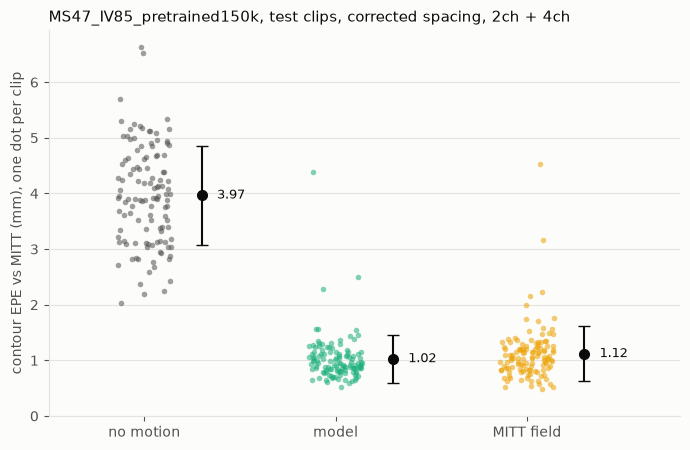

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.6))
strip(ax, {c: anchor[c] for c in cols}, {"no motion": INK_2, "model": VARIANT_COLOUR["pretrained150k"], "MITT field": SERIES[3]})
ax.set_title(f"{ANCHOR_RUN}, test clips, corrected spacing, 2ch + 4ch", fontsize=11, color=INK)
ax.set_ylabel("contour EPE vs MITT (mm), one dot per clip")
ax.set_ylim(0, None)
fig.tight_layout()

### 3b, second part: are MITT's fields on the right frames, and why can the model beat them?

One step at a time, without propagating: each field moves MITT's points from one frame to the next. Under the right frame pairing the step error is smallest. This also checks the in vivo *training* targets, which use the same pairing (`frame<k+1>.flo` for pair k -> k+1).

In [8]:
from motion_estimator.strain.propagate import advect_points

steps = {"no motion": [], "current pairing": [], "one frame earlier": [], "one frame later": []}
for key in anchor.key[:12]:
    dataset, patient, view = key.split("/")
    with np.load(INVIVO_CACHE / dataset / f"{patient}_{view}.npz", allow_pickle=False) as data:
        ref_x, ref_y = data["reference_x"].astype(float), data["reference_y"].astype(float)
        sx, sy = data["spacing_xy"].astype(float)
    flow = np.load(IV_FLOW_CACHE / dataset / patient / view / "flow.npy", mmap_mode="r")
    if flow.shape[0] != len(ref_x) - 2:
        continue

    def step_mm(j, a, b):  # move MITT's frame-a points with field j, compare with MITT's frame b
        x, y = advect_points(np.asarray(flow[j], np.float32).transpose(1, 2, 0),
                             torch.from_numpy(ref_x[a]), torch.from_numpy(ref_y[a]))
        return np.nanmean(np.hypot((x.numpy() - ref_x[b]) * sx, (y.numpy() - ref_y[b]) * sy))

    for j in range(len(ref_x) - 3):   # field j = frame j+2 -> j+3 (1-based), training's pairing
        steps["no motion"].append(np.mean(np.hypot((ref_x[j + 1] - ref_x[j + 2]) * sx, (ref_y[j + 1] - ref_y[j + 2]) * sy)))
        steps["current pairing"].append(step_mm(j, j + 1, j + 2))
        steps["one frame earlier"].append(step_mm(j, j, j + 1))
        steps["one frame later"].append(step_mm(j, j + 2, j + 3))
pd.DataFrame({k: {"mean mm": np.mean(v), "median mm": np.median(v), "steps": len(v)} for k, v in steps.items()}).T.round(3)

,mean mm,median mm,steps
no motion,0.326,0.289,742.0
current pairing,0.156,0.116,742.0
one frame earlier,0.258,0.218,742.0
one frame later,0.259,0.216,742.0


- The current pairing has clearly the smallest step error, so the fields sit on the right frames, for training and for this anchor.
- That error is still not zero, about 0.16 mm per step. MITT's dense field is not an exact copy of its tracked points. Propagated over 40-70 frames it adds up to about 1.1 mm.
- Likely reason the model can beat it: the network learns from many clips and smooths out per-clip noise in the field, so it drifts less along the cycle. Not proven here, but beating the MITT field is not by itself a sign of a bug.

### 3c. Pixel spacing

GE pixels are not square. The paper's MATLAB scaled x by the row spacing and y by the column spacing. This shows what that swap does to each 2ch clip.

In [9]:
spacing = []
for f in sorted(INVIVO_CACHE.glob("*/*.npz")):
    with np.load(f, allow_pickle=False) as d:
        spacing.append({"clip": f"{f.parent.name}/{f.stem}", "column mm": d["spacing_xy"][0], "row mm": d["spacing_xy"][1]})
spacing = pd.DataFrame(spacing)
display(spacing[["column mm", "row mm"]].describe().loc[["count", "mean", "min", "max"]].round(3))

two = scores[scores.view == "2ch"]
d = (two.epe_mm_paper_exact - two.epe_mm).dropna()
print(f"paper spacing minus corrected, per 2ch clip: mean {d.mean():+.3f} mm, range {d.min():+.3f} .. {d.max():+.3f}")

,column mm,row mm
count,236.000,236.000
mean,0.338,0.273
min,0.244,0.200
max,0.464,0.361


paper spacing minus corrected, per 2ch clip: mean -0.090 mm, range -1.016 .. +0.207


## 4. Per fold, and scratch vs pretrained on the same clips

Single folds scatter by about ±0.1 mm from one checkpoint to the next (see PAPER_REPLICATION.md), so read the fold rows together, not one at a time.

In [10]:
two = scores[scores.view == "2ch"]
display(two.pivot_table(index="fold", columns="run", values="epe_mm_paper_exact", aggfunc="mean").round(2))

wide = scores[scores.test == "MS47_IV85"].pivot_table(index="key", columns="variant", values="epe_mm")
if {"scratch", "pretrained150k"} <= set(wide.columns):
    diff = (wide["pretrained150k"] - wide["scratch"]).dropna()
    boot = np.random.default_rng(0).choice(diff.to_numpy(), (5000, len(diff))).mean(axis=1)
    print(f"MS47_IV85, pretrained150k - scratch (corrected, both views): {diff.mean():+.3f} mm, "
          f"95% CI {np.percentile(boot, 2.5):+.3f} .. {np.percentile(boot, 97.5):+.3f}, "
          f"better on {(diff < 0).sum()}/{len(diff)} clips")

run,MS47_IV0,MS47_IV0_pretrained,MS47_IV0_pretrained150k,MS47_IV85,MS47_IV85_pretrained,MS47_IV85_pretrained150k
fold,,,,,,
fold0,NaN,NaN,NaN,1.17,1.18,1.12
fold1,NaN,NaN,NaN,0.93,NaN,0.89
fold2,NaN,NaN,NaN,NaN,NaN,1.02
single,1.75,1.6,1.65,NaN,NaN,NaN


MS47_IV85, pretrained150k - scratch (corrected, both views): -0.075 mm, 95% CI -0.113 .. -0.036, better on 54/78 clips


## 5. What is still not face to face

- **Folds.** Table 2 pools all 6 folds. Here MS47_IV85 pretrained150k has the folds listed in section 1 (the rest are training or queued). Scratch has folds 0-1 only, because folds 2-5 are parked. Once all 6 folds are done the patient set is the paper's, minus the 6 skipped clips.
- **Fold membership.** The paper's fold lists are lost, so the folds were re-drawn. Per-fold numbers do not match the paper patient for patient. The pooled 6-fold mean does.
- **Start.** The paper trained from scratch, so the `pretrained*` rows have no counterpart in the paper.
- **Data.** The synthetic set is new, which is the point of the replication. A difference from the paper is the result, not an error.
- **Per-patient pairing with the paper.** That needs the paper's own contours. Test_3/4/5 (MS12/23/35_IV85) are on F: and pass check 3a, but those tests are not trained yet. The F: folder for MS47_IV85 is not the model Table 2 reports (0.90 vs 1.10 mm).